# Comparing Different Search Strategies: Maze

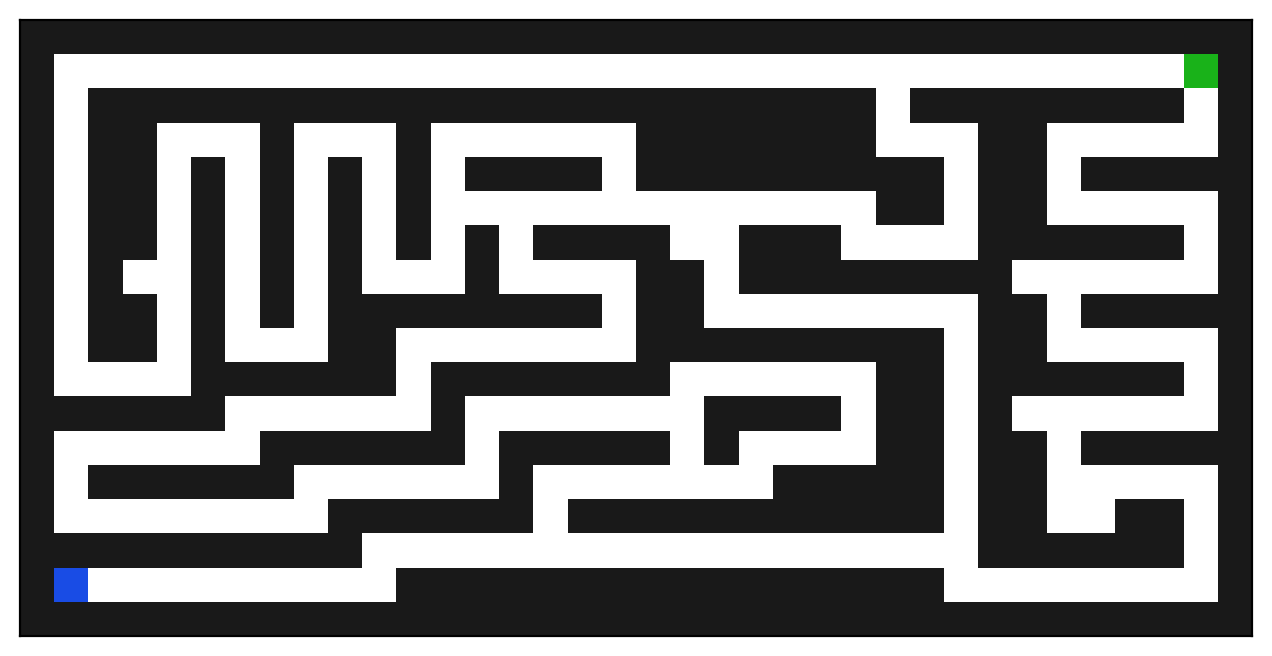

In [1]:
%run maze_helper.py
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import numpy as np

#f = open("small_maze.txt", "r")
f = open("medium_maze.txt", "r")
#f = open("large_maze.txt", "r")    # this has only one solution!
#f = open("open_maze.txt", "r")
#f = open("empty_maze.txt", "r")
#f = open("empty_maze_2.txt", "r")
#f = open("loops_maze.txt", "r")
#f = open("L_maze.txt", "r")
import importlib
import maze_helper as mh
import tree_search_solution as ts
importlib.reload(mh)
importlib.reload(ts)
maze_str = f.read()
maze = parse_maze(maze_str)

show_maze(maze)

My implementation follows the pseudo code from the slides/textbook.

In [2]:
# tree_search_solution.py has my actual implementation (not published)
import tree_search_solution as ts


# order in which we add new states to the frontier
ts.set_order("NESW")
#ts.set_order(random=True)

## Experiments - Uninformed Search

### BFS

In [3]:
%time result = ts.best_first_search(maze, strategy = "BFS", animation = True)
ts.animate_maze(result, frames=24)

CPU times: user 803 μs, sys: 61 μs, total: 864 μs
Wall time: 2.09 ms


### DFS 

This implementation does not use a reached data structure and has space complexity $O(bm)$ instead of $O(b^m)$ when we reuse the tree search algorithm from BFS!

We need to check for all cycles. If we do not break all cycles correctly, then we can end up in an infinite loop.

In [4]:
ts.set_order("NESW")

%time result = ts.DFS(maze, vis = False, max_tries = 1200, debug_reached = True, animation = True)
ts.animate_maze(result, frames=24)

CPU times: user 1.89 ms, sys: 26 μs, total: 1.91 ms
Wall time: 1.91 ms


Note on the visualization: I use gray for areas that the algorithm has explored, but DFS has already removed it from memory so they are shown white.

The exploration order (order used in the expand function) is very important for DFS! DFS uses LIFO so the directions come from the stack in reverse order.

I set the exploration order so that South will be explored before West.

In [5]:
ts.set_order("ENWS")

%time result = ts.DFS(maze, vis = False, max_tries = 1200, debug_reached = True, animation = True)
ts.animate_maze(result, frames=24)

CPU times: user 1.44 ms, sys: 68 μs, total: 1.51 ms
Wall time: 1.53 ms


The best exploration order depends on the Maze, so we probably should rather use random exploration. Here the order is randomized in at each step. It will produce sometimes give good and sometimes bad solutions and can be used with multi[ple restarts.

In [6]:
import random
random.seed(20261009)
ts.set_order(random=True)

%time result = ts.DFS(maze, vis = False, max_tries = 1200, debug_reached = True, animation = True)
ts.animate_maze(result, frames=24)

CPU times: user 2.01 ms, sys: 121 μs, total: 2.13 ms
Wall time: 2.13 ms


## Experiments - Informed Search

### Greedy Best-First Search (GBFS)

Walks towards the goal using the heuristic. It is greedy and not guaranteed to find the optimal solution.

In [7]:
# set the heuristic to Manhattan distance
ts.heuristic = ts.manhattan

In [8]:
ts.set_order('NESW',random=False)

%time result = ts.best_first_search(maze, strategy = "GBFS", animation = True)
ts.animate_maze(result, frames=24)

CPU times: user 417 μs, sys: 32 μs, total: 449 μs
Wall time: 438 μs


### A* Search

Uses an admissible heuristic and is guaranteed to find the optimal solution. It needs to explore a little more compared to GBFS. 

In [9]:
ts.set_order('NESW',random=False)

%time result = ts.best_first_search(maze, strategy = "A*", animation = True)
ts.animate_maze(result, frames=24)

CPU times: user 610 μs, sys: 91 μs, total: 701 μs
Wall time: 664 μs


## Bài 3 – Nhận xét từ animation
BFS khảo sát các lớp trạng thái theo độ sâu, còn DFS đi sâu trước; đổi thứ tự sinh successor NESW/ENWS hoặc seed làm thay đổi đường đi. Các animation chỉ lấy 24 khung hình để giảm dung lượng. Các lượt DFS được giới hạn 1200 pop để tránh Run All treo: dừng vì giới hạn **không có nghĩa** mê cung vô nghiệm. Số liệu chính của Bài 3 được kiểm chứng trên các bảng CSV và hình trong 02_Maze_Example.ipynb.